# Cropland Area in Kansas Groundwater Management District 4 (MODIS, 2001–2023)

Groundwater Management District 4 (GMD4) in northwest Kansas sits on top of the Ogallala (High Plains) aquifer,
and much of its farmland depends on groundwater. In this notebook I track how much cropland there has been in GMD4
every year since 2001, using the MODIS land cover product (`MODIS/061/MCD12Q1`, 500 m) in Google Earth Engine.

I count two MODIS land cover classes as cropland:

| Class | What it is |
|---|---|
| 12 | Croplands |
| 14 | Cropland / natural vegetation mosaic (fields mixed with grass or trees) |

**What you get:** a yearly table of cropland area, trend statistics, a breakdown by county, and maps of where
cropland was gained or lost between the first and last year.

## 1. Setup

In [1]:
import os, io
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import requests
from PIL import Image
from scipy import stats

C:\Users\moham\anaconda3\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


In [2]:
ee.Authenticate(auth_mode="localhost")
ee.Initialize(project="plug in your GEE username here!")

## 2. Study area and settings

GMD4 is not a standard boundary in Earth Engine, so there are two ways to define it:

1. **Exact boundary (best):** download the GMD boundaries from the Kansas Geological Survey or the Kansas Department of
   Agriculture, upload the GMD4 polygon to Earth Engine as an asset, and put its path in `GMD4_ASSET`.
2. **County approximation (default):** if no asset is given, I use the northwest Kansas counties that make up most of GMD4.
   The district's edges do not follow county lines exactly, so treat these areas as approximate.

In [3]:
# Folders where I save tables and figures
FIG_DIR, OUT_DIR = "figures/gmd4", "outputs/gmd4"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Option 1: the exact GMD4 boundary uploaded as an Earth Engine asset (leave as None to use counties)
GMD4_ASSET = None   # e.g. "projects/your-project/assets/gmd4_boundary"

# Option 2: counties that make up most of GMD4 (used when no asset is given)
GMD4_COUNTIES = ["Cheyenne", "Rawlins", "Decatur", "Sherman", "Thomas", "Sheridan"]

kansas_counties = (ee.FeatureCollection("TIGER/2018/Counties")
                     .filter(ee.Filter.eq("STATEFP", "20")))      # 20 is the state code for Kansas

if GMD4_ASSET:
    roi = ee.FeatureCollection(GMD4_ASSET).geometry()
    ROI_NAME = "GMD4"
else:
    roi = kansas_counties.filter(ee.Filter.inList("NAME", GMD4_COUNTIES)).union(100).geometry()
    ROI_NAME = "GMD4 (county approximation)"

# The counties that touch the study area, used for the county breakdown
counties = kansas_counties.filterBounds(roi)

START_YEAR, END_YEAR = 2001, 2023   # MODIS has one land cover map per year
SCALE = 500                         # MODIS pixel size in metres
CROP_CLASSES = {12: "Croplands", 14: "Cropland/natural vegetation mosaic"}

print(f"Study area: {ROI_NAME}, about {roi.area(100).divide(1e6).getInfo():,.0f} km²")

Study area: GMD4 (county approximation), about 15,556 km²


## 3. Yearly cropland area

In [4]:
# Load the yearly MODIS land cover maps (IGBP classification)
modis = (ee.ImageCollection("MODIS/061/MCD12Q1")
           .select("LC_Type1")
           .filterDate(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31")
           .sort("system:time_start"))

# Area of each pixel in km², so adding up pixels gives an area instead of a pixel count
pixel_km2 = ee.Image.pixelArea().divide(1e6)

def cropland_area(img):
    # For one year: turn each cropland class into an area image (pixel area where the class is present, 0 elsewhere)
    lc = img.select("LC_Type1")
    croplands = lc.eq(12).multiply(pixel_km2).rename("croplands_km2")
    mosaic = lc.eq(14).multiply(pixel_km2).rename("mosaic_km2")
    total = lc.eq(12).Or(lc.eq(14)).multiply(pixel_km2).rename("total_km2")
    everything = pixel_km2.rename("roi_km2")
    # Add up the areas inside the study area
    sums = ee.Image.cat(croplands, mosaic, total, everything).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi, scale=SCALE, maxPixels=1e13, tileScale=4)
    return ee.Feature(None, sums).set("year", img.date().get("year"))

rows = [f["properties"] for f in modis.map(cropland_area).getInfo()["features"]]

df = (pd.DataFrame(rows).astype({"year": int}).set_index("year").sort_index()
        [["croplands_km2", "mosaic_km2", "total_km2", "roi_km2"]])
df["share_pct"] = 100 * df["total_km2"] / df["roi_km2"]     # how much of the district is cropland
df["change_km2"] = df["total_km2"].diff()                   # change from the year before
df.round(2).to_csv(f"{OUT_DIR}/gmd4_cropland_area_annual.csv")
df.round(1)

,croplands_km2,mosaic_km2,total_km2,roi_km2,share_pct,change_km2
year,,,,,,
2001,7095.6,0,7095.6,15570.0,45.6,NaN
2002,4551.0,0,4551.0,15570.0,29.2,-2544.7
2003,5016.5,0,5016.5,15570.0,32.2,465.5
2004,5785.7,0,5785.7,15570.0,37.2,769.2
2005,5958.1,0,5958.1,15570.0,38.3,172.4
2006,5594.7,0,5594.7,15570.0,35.9,-363.4
2007,6835.3,0,6835.3,15570.0,43.9,1240.6
2008,6068.3,0,6068.3,15570.0,39.0,-767.0
2009,6003.6,0,6003.6,15570.0,38.6,-64.7


## 4. How much has cropland changed?

In [5]:
years = df.index.values
area = df["total_km2"].values

# Straight-line trend, plus two tests that are less sensitive to unusual years
ols = stats.linregress(years, area)
ts_slope, ts_int, ts_lo, ts_hi = stats.theilslopes(area, years)
tau, mk_p = stats.kendalltau(years, area)

first, last = df.iloc[0], df.iloc[-1]
summary = pd.Series({
    "Period": f"{years[0]}–{years[-1]}",
    "Cropland in first year (km²)": first.total_km2,
    "Cropland in last year (km²)": last.total_km2,
    "Net change (km²)": last.total_km2 - first.total_km2,
    "Net change (%)": 100 * (last.total_km2 / first.total_km2 - 1),
    "Average share of district in cropland (%)": df["share_pct"].mean(),
    "Year with most cropland": int(df.total_km2.idxmax()),
    "Year with least cropland": int(df.total_km2.idxmin()),
    "Linear trend (km²/yr)": ols.slope,
    "Linear trend p-value": ols.pvalue,
    "Theil–Sen trend (km²/yr)": ts_slope,
    "Mann–Kendall p-value": mk_p,
}, name="value")
summary.to_csv(f"{OUT_DIR}/gmd4_cropland_trend_summary.csv")
summary.to_frame()

,value
Period,2001–2023
Cropland in first year (km²),7095.63706
Cropland in last year (km²),7175.010705
Net change (km²),79.373645
Net change (%),1.118626
Average share of district in cropland (%),37.529189
Year with most cropland,2023
Year with least cropland,2002
Linear trend (km²/yr),30.183441
Linear trend p-value,0.221711


## 5. Figures

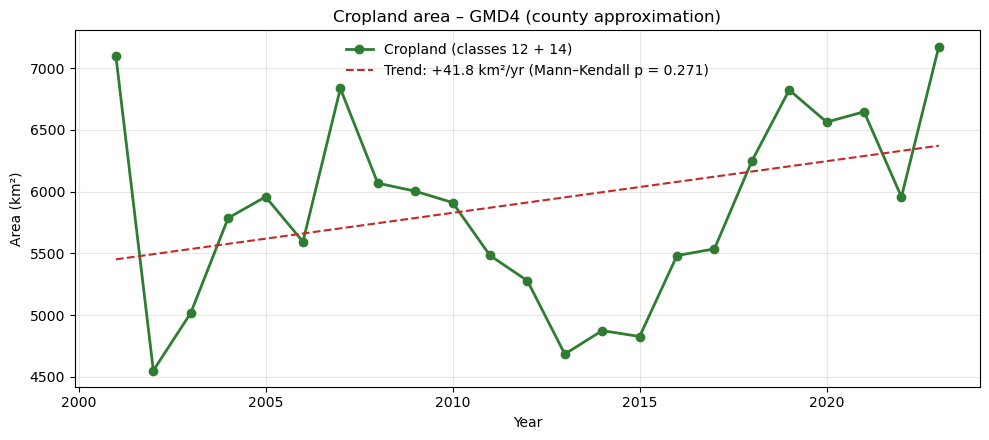

In [6]:
# Total cropland every year, with the trend line
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(years, area, "o-", color="#2e7d32", lw=2, label="Cropland (classes 12 + 14)")
ax.plot(years, ts_int + ts_slope * years, "--", color="#c62828",
        label=f"Trend: {ts_slope:+.1f} km²/yr (Mann–Kendall p = {mk_p:.3f})")
ax.set(xlabel="Year", ylabel="Area (km²)", title=f"Cropland area – {ROI_NAME}")
ax.grid(alpha=0.3); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/01_gmd4_cropland_timeseries.png"); plt.show()

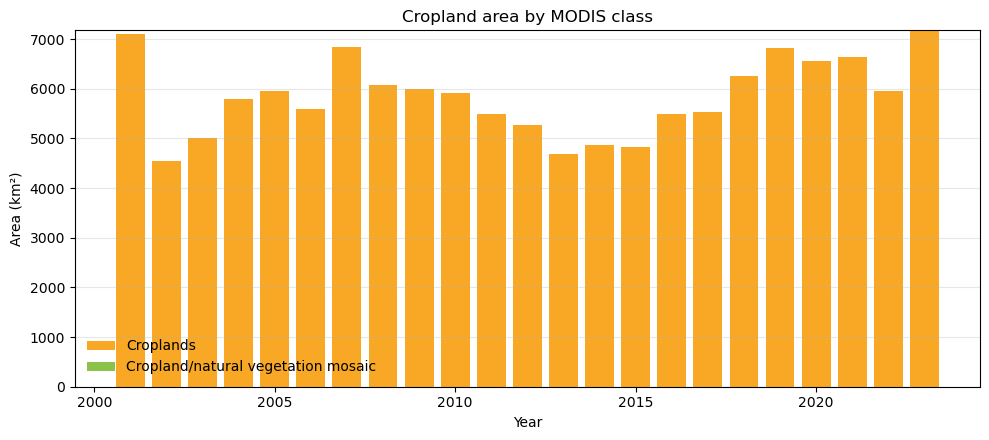

In [7]:
# The same total, split into the two cropland classes
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(years, df["croplands_km2"], color="#f9a825", label=CROP_CLASSES[12])
ax.bar(years, df["mosaic_km2"], bottom=df["croplands_km2"], color="#8bc34a", label=CROP_CLASSES[14])
ax.set(xlabel="Year", ylabel="Area (km²)", title="Cropland area by MODIS class")
ax.legend(frameon=False, loc="lower left"); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/02_gmd4_cropland_by_class.png"); plt.show()

## 6. Cropland by county

Here I split the cropland area by county. Only the part of each county inside the study area is counted.

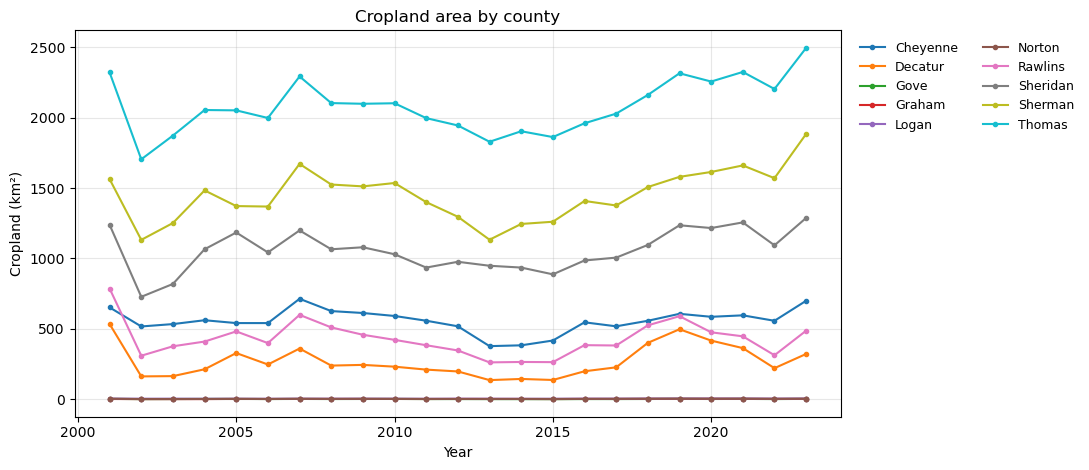

,2001 (km²),2023 (km²),Change (km²),Change (%)
county,,,,
Rawlins,786.2,486.7,-299.5,-38.1
Decatur,534.1,321.5,-212.6,-39.8
Gove,2.4,2.3,-0.1,-2.8
Norton,3.2,3.3,0.1,3.9
Logan,4.3,4.9,0.5,12.7
Graham,1.7,2.4,0.7,42.8
Cheyenne,652.0,699.3,47.3,7.3
Sheridan,1238.8,1287.6,48.8,3.9
Thomas,2321.0,2495.3,174.3,7.5


In [8]:
def county_cropland(img):
    # Cropland area for one year, clipped to the study area and added up within each county
    year = img.date().get("year")
    crop = img.select("LC_Type1").eq(12).Or(img.select("LC_Type1").eq(14)).multiply(pixel_km2).clip(roi)
    per_county = crop.rename("cropland_km2").reduceRegions(collection=counties, reducer=ee.Reducer.sum(), scale=SCALE)
    return per_county.map(lambda f: ee.Feature(None, {"county": f.get("NAME"), "year": year,
                                                       "cropland_km2": f.get("sum")}))

county_rows = [f["properties"] for f in modis.map(county_cropland).flatten().getInfo()["features"]]
by_county = (pd.DataFrame(county_rows).astype({"year": int})
               .pivot_table(index="year", columns="county", values="cropland_km2"))
by_county = by_county.loc[:, by_county.mean() > 1]          # leave out counties that barely touch the area
by_county.round(1).to_csv(f"{OUT_DIR}/gmd4_cropland_by_county.csv")

county_change = pd.DataFrame({
    f"{years[0]} (km²)": by_county.iloc[0],
    f"{years[-1]} (km²)": by_county.iloc[-1],
    "Change (km²)": by_county.iloc[-1] - by_county.iloc[0],
    "Change (%)": 100 * (by_county.iloc[-1] / by_county.iloc[0] - 1),
}).sort_values("Change (km²)")

fig, ax = plt.subplots(figsize=(11, 4.8))
for county in by_county.columns:
    ax.plot(by_county.index, by_county[county], "o-", ms=3, label=county)
ax.set(xlabel="Year", ylabel="Cropland (km²)", title="Cropland area by county")
ax.legend(frameon=False, fontsize=9, ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/03_gmd4_cropland_by_county.png"); plt.show()
county_change.round(1)

## 7. Where cropland was gained or lost

I compare the first and last year pixel by pixel. The maps are saved as images so they show up on GitHub.

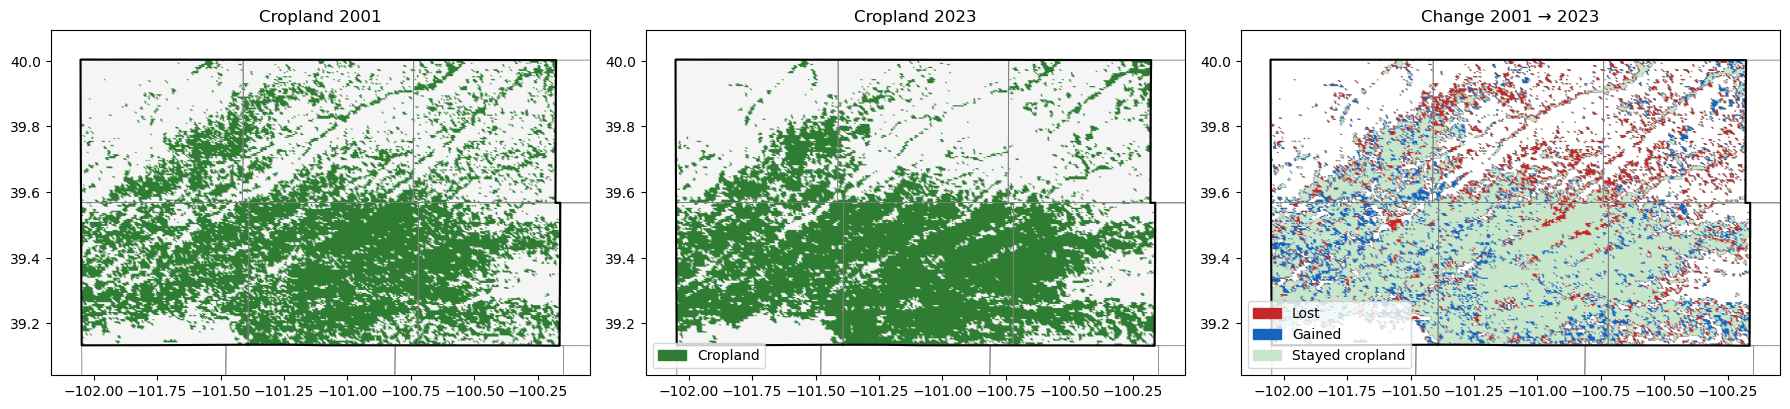

gained_km2    1503.2
lost_km2      1423.8
stable_km2    5671.8
net_km2         79.4
dtype: float64

In [9]:
def to_array(vis_image, view):
    # Ask Earth Engine for a PNG of the map and turn it into an array that matplotlib can show
    url = vis_image.getThumbURL({"region": view, "dimensions": 1200, "crs": "EPSG:4326", "format": "png"})
    return np.array(Image.open(io.BytesIO(requests.get(url, timeout=300).content)))

def draw_outline(ax, g, **kw):
    # Draw polygon outlines (works for single polygons and multi-part shapes)
    if g["type"] == "Polygon":
        ring = np.array(g["coordinates"][0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "MultiPolygon":
        for poly in g["coordinates"]:
            ring = np.array(poly[0]); ax.plot(ring[:, 0], ring[:, 1], **kw)
    elif g["type"] == "GeometryCollection":
        for sub in g["geometries"]:
            draw_outline(ax, sub, **kw)

def is_crop(img):
    lc = img.select("LC_Type1")
    return lc.eq(12).Or(lc.eq(14))

crop_first = is_crop(modis.first())
crop_last = is_crop(modis.sort("system:time_start", False).first())

# Combine the two years into one code: 1 = lost, 2 = gained, 3 = cropland in both years
change = crop_first.add(crop_last.multiply(2))
change = change.updateMask(change.gt(0)).clip(roi)

view = roi.bounds().buffer(10000).bounds()
crop_vis = {"min": 0, "max": 1, "palette": ["f5f5f5", "2e7d32"]}
maps = [
    (to_array(crop_first.clip(roi).visualize(**crop_vis), view), f"Cropland {years[0]}"),
    (to_array(crop_last.clip(roi).visualize(**crop_vis), view), f"Cropland {years[-1]}"),
    (to_array(change.visualize(min=1, max=3, palette=["c62828", "1565c0", "c8e6c9"]), view),
     f"Change {years[0]} → {years[-1]}"),
]

b = np.array(view.coordinates().getInfo()[0])
extent = [b[:, 0].min(), b[:, 0].max(), b[:, 1].min(), b[:, 1].max()]
county_shapes = counties.map(lambda f: f.simplify(200)).getInfo()["features"]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (arr, title) in zip(axes, maps):
    ax.imshow(arr, extent=extent)
    for f in county_shapes:
        draw_outline(ax, f["geometry"], color="gray", lw=0.6)
    draw_outline(ax, roi.getInfo(), color="black", lw=1.5)
    ax.set_title(title); ax.set_xlim(extent[:2]); ax.set_ylim(extent[2:])
    ax.set_aspect(1 / np.cos(np.deg2rad(39.4)))
axes[1].legend(handles=[mpatches.Patch(color="#2e7d32", label="Cropland")], loc="lower left")
axes[2].legend(handles=[mpatches.Patch(color=col, label=lab) for col, lab in
                        [("#c62828", "Lost"), ("#1565c0", "Gained"), ("#c8e6c9", "Stayed cropland")]],
               loc="lower left")
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/04_gmd4_cropland_maps.png"); plt.show()

# Total area gained, lost and unchanged
areas = ee.Image.cat(change.eq(1).multiply(pixel_km2).rename("lost_km2"),
                     change.eq(2).multiply(pixel_km2).rename("gained_km2"),
                     change.eq(3).multiply(pixel_km2).rename("stable_km2")).reduceRegion(
    ee.Reducer.sum(), roi, SCALE, maxPixels=1e13).getInfo()
change_table = pd.Series(areas).round(1)
change_table["net_km2"] = round(change_table["gained_km2"] - change_table["lost_km2"], 1)
change_table.to_csv(f"{OUT_DIR}/gmd4_cropland_change.csv")
change_table

## 8. Notes

- **Data:** Friedl & Sulla-Menashe (2022), MODIS/Terra+Aqua Land Cover Type Yearly L3 Global 500 m (MCD12Q1 v6.1);
  US Census TIGER county boundaries.
- MODIS pixels are 500 m, so small fields and field edges get lumped together. The numbers are good for trends,
  less so for exact acreage; USDA's Cropland Data Layer gives finer detail from 2008 onwards.
- MODIS land cover does not separate irrigated from dryland crops. For groundwater questions in GMD4, an irrigation
  map (for example the Landsat-based LANID irrigation dataset) would be a useful next step.
- Year-to-year jumps can come from the classification itself (fields switching between classes 12 and 14), so look at the
  combined total and the long-term trend rather than single-year changes.